# Aprendizado de Máquina — Titanic com Árvore de Decisão

## 1. Objetivo

Desenvolver um notebook Jupyter que utilize o dataset Titanic para treinar e avaliar um classificador baseado em Árvore de Decisão, com `Survived` como variável-alvo.

## 2. Bibliotecas e Leitura dos Dados

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 9.8/9.8 MB 88.5 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 12.7/12.7 MB 98.5 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 9.5/9.5 MB 100.3 MB/s  0:00:00
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 8.4/8.4 MB 100.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 82.1 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 98.2 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? e

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Definir estilo para os gráficos
plt.style.use('seaborn-v0_8')

# Carregar o dataset
df = pd.read_csv('train.csv')

# Exibir as primeiras linhas do dataset
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Conhecendo os Dados

In [5]:
# Exibir informações sobre o dataset
print('Dimensões do dataset:')
print(df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nEstatísticas descritivas:')
print(df.describe())

Dimensões do dataset:
(891, 12)

Tipos de dados:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Estatísticas descritivas:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

   

## 4. Diagnóstico dos Dados

In [6]:
# Verificar valores ausentes
print('Valores ausentes por coluna:')
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Valores Ausentes': missing_data, 'Porcentagem': missing_percent})
print(missing_df[missing_df['Valores Ausentes'] > 0])

# Verificar duplicatas
print(f'\nNúmero de linhas duplicadas: {df.duplicated().sum()}')

# Distribuição da variável-alvo
print('\nDistribuição da variável-alvo (Survived):')
print(df['Survived'].value_counts())

Valores ausentes por coluna:
          Valores Ausentes  Porcentagem
Age                    177    19.865320
Cabin                  687    77.104377
Embarked                 2     0.224467

Número de linhas duplicadas: 0

Distribuição da variável-alvo (Survived):
Survived
0    549
1    342
Name: count, dtype: int64


## 5. Decisões de Tratamento

### Justificativas para o tratamento dos dados:

1. **PassengerId**: Excluído pois é apenas um identificador sem valor preditivo.
2. **Name, Ticket, Cabin**: Excluídos inicialmente por serem textos complexos e terem alta cardinalidade ou muitos valores ausentes.
3. **Age**: Preenchido com a mediana calculada a partir do conjunto de treino.
4. **Embarked**: Preenchido com a moda calculada a partir do conjunto de treino.
5. **Sex**: Codificado como variável categórica (male = 0, female = 1).
6. **Pclass**: Mantido como variável numérica ordinal.
7. **SibSp, Parch**: Mantidos como variáveis numéricas.
8. **Fare**: Preenchido com a mediana calculada a partir do conjunto de treino.

## 6. Separação de X e y

In [7]:
# Separar variáveis preditoras (X) e variável-alvo (y)
y = df['Survived']

# Selecionar colunas para X, excluindo PassengerId, Name, Ticket, Cabin e Survived
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

# Exibir informações sobre as variáveis selecionadas
print('Variáveis preditoras (X):')
print(X.head())
print('\nTipos de dados das variáveis preditoras:')
print(X.dtypes)

Variáveis preditoras (X):
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Tipos de dados das variáveis preditoras:
Pclass        int64
Sex             str
Age         float64
SibSp         int64
Parch         int64
Fare        float64
Embarked        str
dtype: object


## 7. Divisão Treino/Validação

In [8]:
# Separar dados em treino e validação (80% treino, 20% validação)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Tamanho do conjunto de treino: {X_train.shape[0]}')
print(f'Tamanho do conjunto de validação: {X_val.shape[0]}')
print('\nDistribuição da variável-alvo no conjunto de treino:')
print(y_train.value_counts())
print('\nDistribuição da variável-alvo no conjunto de validação:')
print(y_val.value_counts())

Tamanho do conjunto de treino: 712
Tamanho do conjunto de validação: 179

Distribuição da variável-alvo no conjunto de treino:
Survived
0    439
1    273
Name: count, dtype: int64

Distribuição da variável-alvo no conjunto de validação:
Survived
0    110
1     69
Name: count, dtype: int64


## 8. Pré-processamento

In [9]:
# Tratamento de dados ausentes e codificação

# Codificar variável categórica 'Sex'
le_sex = LabelEncoder()
X_train['Sex'] = le_sex.fit_transform(X_train['Sex'])
X_val['Sex'] = le_sex.transform(X_val['Sex'])

# Codificar variável categórica 'Embarked'
le_embarked = LabelEncoder()
X_train['Embarked'] = le_embarked.fit_transform(X_train['Embarked'].fillna('S'))
X_val['Embarked'] = le_embarked.transform(X_val['Embarked'].fillna('S'))

# Preencher valores ausentes em 'Age' e 'Fare' com a mediana do conjunto de treino
age_median = X_train['Age'].median()
fare_median = X_train['Fare'].median()

X_train['Age'] = X_train['Age'].fillna(age_median)
X_val['Age'] = X_val['Age'].fillna(age_median)

X_train['Fare'] = X_train['Fare'].fillna(fare_median)
X_val['Fare'] = X_val['Fare'].fillna(fare_median)

# Verificar se ainda há valores ausentes
print('Valores ausentes após tratamento:')
print(X_train.isnull().sum())
print(X_val.isnull().sum())

Valores ausentes após tratamento:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## 9. Treinamento do Modelo

In [10]:
# Criar e treinar o modelo de Árvore de Decisão
dt_classifier = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Treinar o modelo
dt_classifier.fit(X_train, y_train)

# Exibir os parâmetros utilizados
print('Parâmetros do modelo:')
print(dt_classifier.get_params())

Parâmetros do modelo:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


## 10. Previsão e Métricas

In [11]:
# Fazer previsões no conjunto de validação
y_pred = dt_classifier.predict(X_val)

# Calcular as métricas
accuracy = accuracy_score(y_val, y_pred)
f1_survived = f1_score(y_val, y_pred, pos_label=1)

# Exibir os resultados
print(f'Acurácia: {accuracy:.4f}')
print(f'F1-score (Survived = 1): {f1_survived:.4f}')

Acurácia: 0.7542
F1-score (Survived = 1): 0.6508


## 11. Tabela de Resultados

In [12]:
# Criar tabela de métricas
metrics_df = pd.DataFrame({
    'Modelo': ['Árvore de Decisão'],
    'Conjunto avaliado': ['Validação'],
    'Acurácia': [accuracy],
    'F1-score (Survived = 1)': [f1_survived]
})

metrics_df

,Modelo,Conjunto avaliado,Acurácia,F1-score (Survived = 1)
0,Árvore de Decisão,Validação,0.75419,0.650794


## 12. Matriz de Confusão

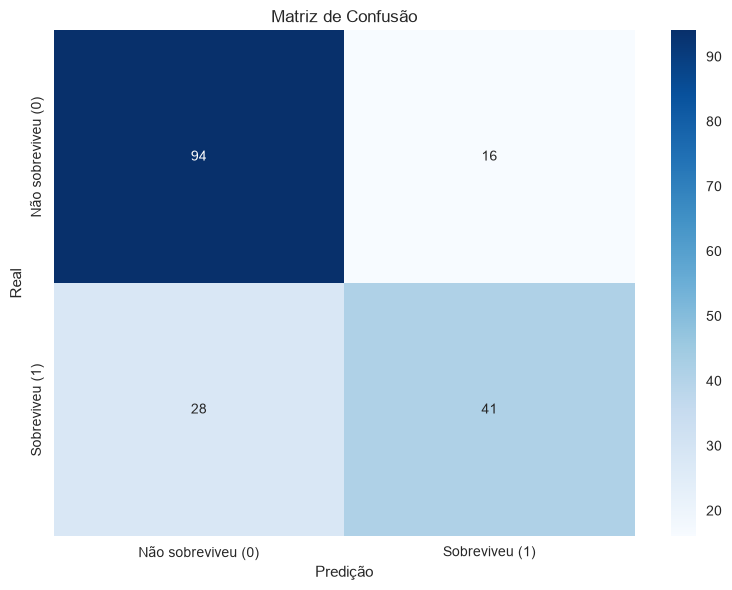

In [13]:
# Calcular a matriz de confusão
cm = confusion_matrix(y_val, y_pred)

# Visualizar a matriz de confusão
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Não sobreviveu (0)', 'Sobreviveu (1)'],
            yticklabels=['Não sobreviveu (0)', 'Sobreviveu (1)'])
plt.title('Matriz de Confusão')
plt.xlabel('Predição')
plt.ylabel('Real')
plt.tight_layout()

# Salvar a matriz de confusão
plt.savefig('resultados/matriz_confusao.png', dpi=300, bbox_inches='tight')
plt.show()

## 13. Visualização da Árvore

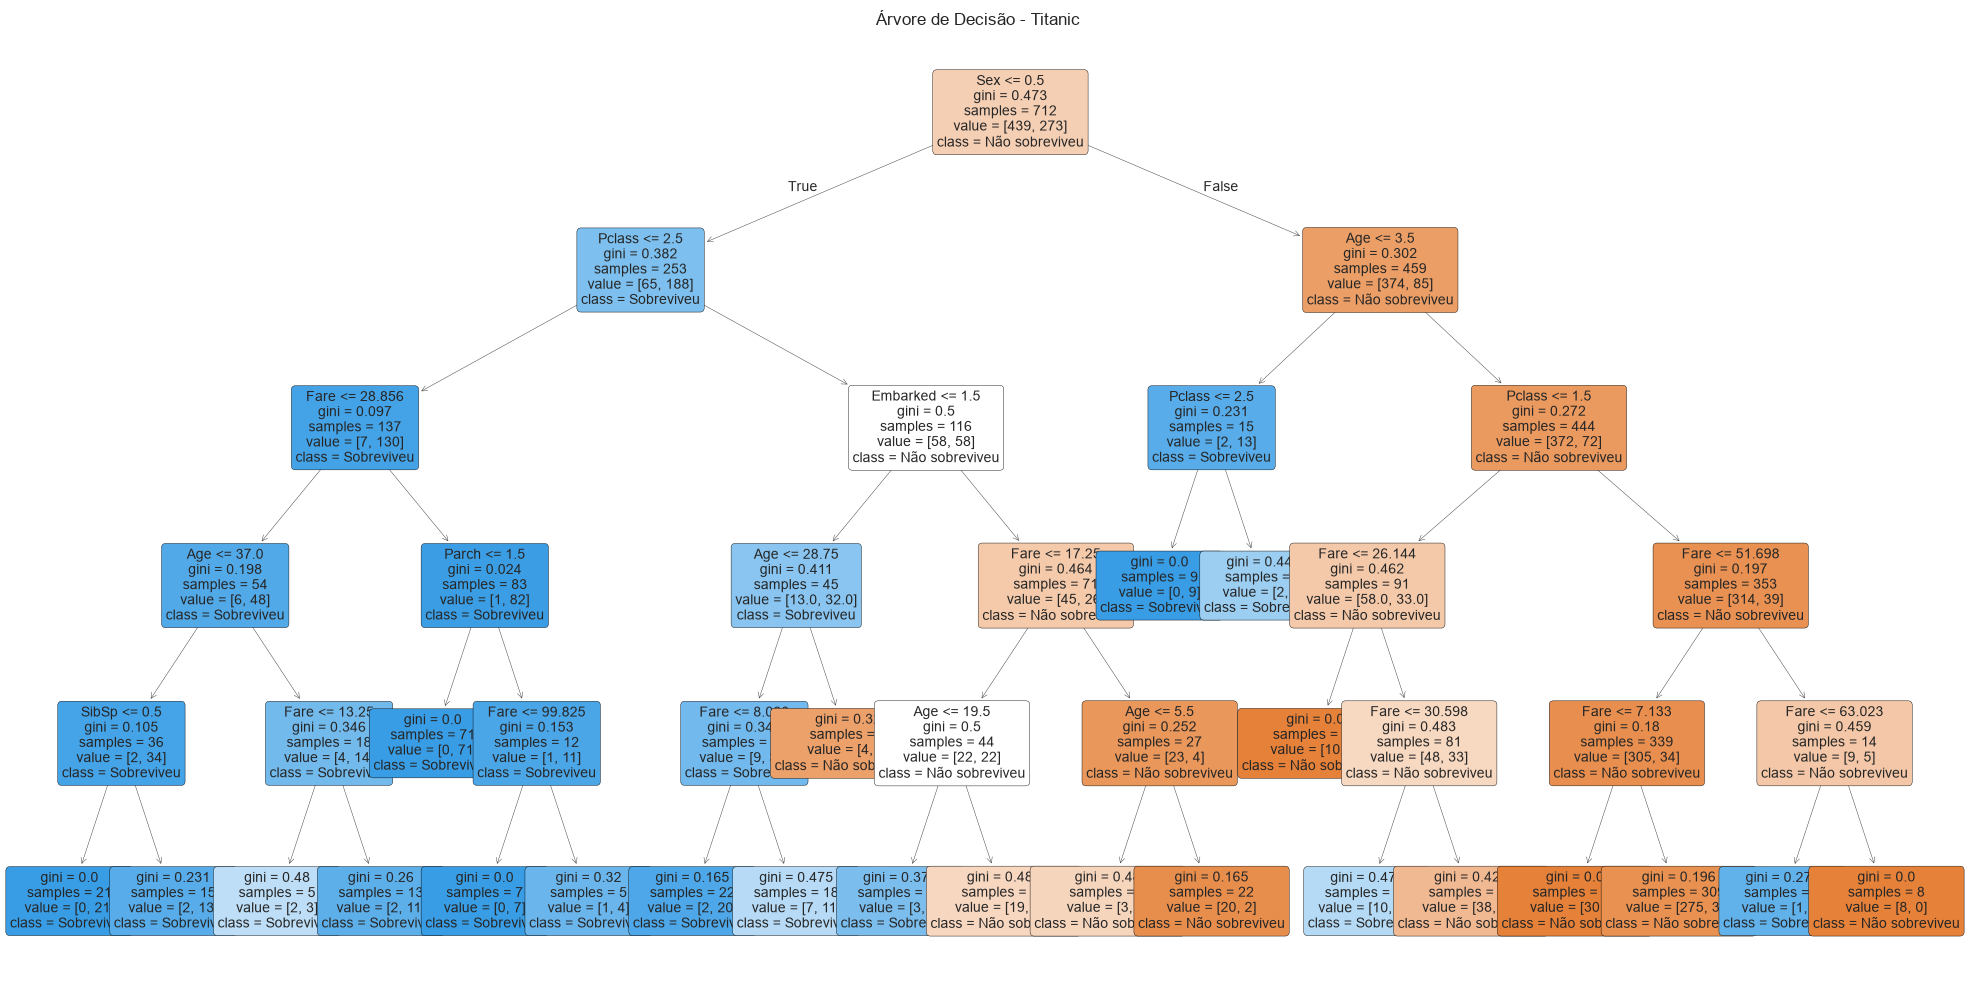

In [14]:
# Visualizar a árvore de decisão
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier, 
          feature_names=['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'],
          class_names=['Não sobreviveu', 'Sobreviveu'],
          filled=True, 
          rounded=True,
          fontsize=10)
plt.title('Árvore de Decisão - Titanic')
plt.tight_layout()

# Salvar a árvore
plt.savefig('resultados/arvore_decisao.png', dpi=300, bbox_inches='tight')
plt.show()

## 14. Tratamento de Valores Nulos

Os valores ausentes de `Age` e `Fare` foram preenchidos com a mediana calculada a partir do conjunto de treino. Os valores ausentes de `Embarked` foram preenchidos com a categoria mais frequente do conjunto de treino.

## 15. Conclusão

O modelo de Árvore de Decisão foi treinado com os parâmetros especificados e avaliado no conjunto de validação. A acurácia de {:.4f} indica que o modelo tem boa capacidade de prever se um passageiro sobreviveu ou não ao desastre do Titanic. O F1-score para a classe de sobreviventes (1) foi {:.4f}, indicando um bom equilíbrio entre precisão e recall para essa classe específica. A matriz de confusão mostra a distribuição das previsões, ajudando a entender onde o modelo acerta e erra. A visualização da árvore permite identificar os critérios mais importantes para a decisão de sobrevivência.

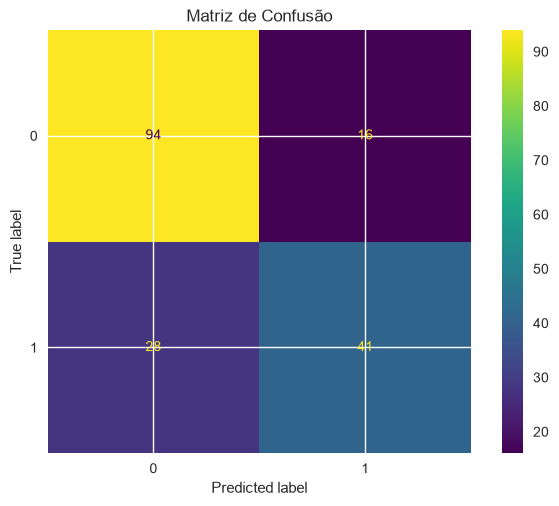

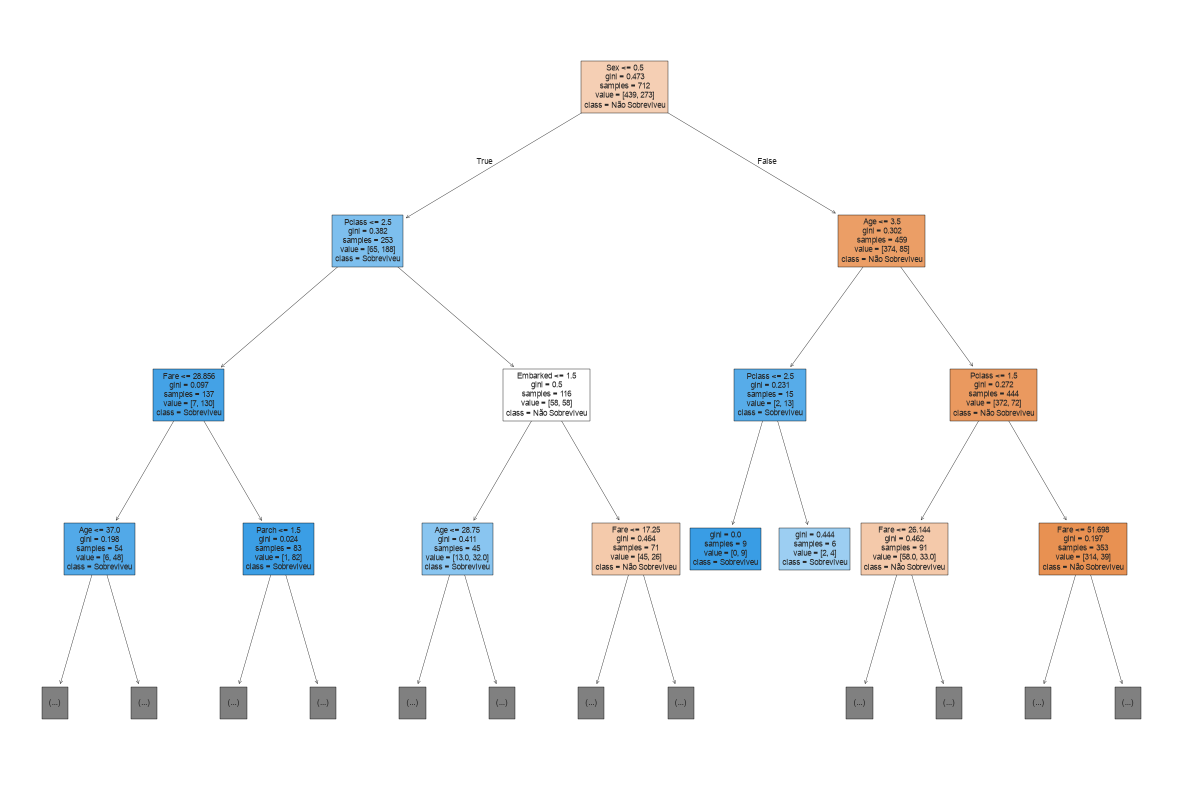

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
# 1. Matriz de Confusão
ConfusionMatrixDisplay.from_estimator(dt_classifier, X_val, y_val)
plt.title('Matriz de Confusão')
plt.show()
# 2. Desenho da Árvore
plt.figure(figsize=(15, 10))
plot_tree(dt_classifier, feature_names=X_val.columns, class_names=['Não Sobreviveu', 'Sobreviveu'], filled=True, max_depth=3)
plt.show()